In [1]:
%pip install -q transformers torchvision tqdm pandas matplotlib

**1. Importing Libraries**


In [2]:
import json
import math
import os
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision.datasets import CelebA
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


**2. Mounting Google Drive and Configuring Paths**

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not running inside Colab, or Drive already unavailable:", e)

PROJECT_ROOT = Path("/content/drive/MyDrive/DL_Project")

DATA_ROOT = PROJECT_ROOT / "data"
SRC_ROOT = PROJECT_ROOT / "src"
THREAD2_DIR = SRC_ROOT / "thread2_gde"

SRC_ROOT.mkdir(parents=True, exist_ok=True)
THREAD2_DIR.mkdir(parents=True, exist_ok=True)

EVAL_PATH = DATA_ROOT / "celeba_evaluation.json"
DB_PATH = SRC_ROOT / "db.pt"
DIRECTIONS_CACHE_PATH = THREAD2_DIR / "gde_attribute_directions.pt"

CELEBA_DIR = DATA_ROOT / "celeba"
ZIP_PATH = CELEBA_DIR / "img_align_celeba.zip"
PARTITION_PATH = CELEBA_DIR / "list_eval_partition.txt"
IMG_DIR = CELEBA_DIR / "img_align_celeba"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_ROOT:", DATA_ROOT)
print("SRC_ROOT:", SRC_ROOT)
print("THREAD2_DIR:", THREAD2_DIR)
print("EVAL_PATH exists:", EVAL_PATH.exists())
print("DB_PATH exists:", DB_PATH.exists())
print("IMG_DIR exists:", IMG_DIR.exists())

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/DL_Project
DATA_ROOT: /content/drive/MyDrive/DL_Project/data
SRC_ROOT: /content/drive/MyDrive/DL_Project/src
THREAD2_DIR: /content/drive/MyDrive/DL_Project/src/thread2_gde
EVAL_PATH exists: True
DB_PATH exists: True
IMG_DIR exists: True


In [4]:
test_filenames = []

with open(PARTITION_PATH, "r") as f:
    for line in f:
        filename, split_id = line.strip().split()
        if split_id == "2":
            test_filenames.append(filename)

print("Number of test images:", len(test_filenames))
print("First 5:", test_filenames[:5])
print("Last 5:", test_filenames[-5:])

Number of test images: 19962
First 5: ['182638.jpg', '182639.jpg', '182640.jpg', '182641.jpg', '182642.jpg']
Last 5: ['202595.jpg', '202596.jpg', '202597.jpg', '202598.jpg', '202599.jpg']


*3. Unzipping Images*

In [22]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    zip_names = set(z.namelist())

    for filename in tqdm(test_filenames, desc="Extracting CelebA test images", unit="img"):
        member_name = f"img_align_celeba/{filename}"

        if member_name not in zip_names:
            print("Missing inside zip:", member_name)
            continue

        z.extract(member_name, CELEBA_DIR)

print("Done extracting test images.")

Extracting CelebA test images:   0%|          | 0/19962 [00:00<?, ?img/s]

Done extracting test images.


**4. Configuration**


In [5]:
CLIP_VERSION = "openai/clip-vit-base-patch32"

FORCE_REBUILD_IMAGE_DB = False
FORCE_REBUILD_DIRECTIONS = False
DOWNLOAD_CELEBA = False

# GDE composition strength. These values are selected using the validation split.
ALPHA = 0.35
ALPHA_VALUES = [0.05, 0.1, 0.2, 0.35, 0.5]

# rho = 0.0 means pure Thread 2 GDE.
# rho > 0.0 means identity-preserving hybrid retrieval.
RHO_VALUES = [0.0, 0.5, 0.7, 0.8, 0.9]

TEXT_PROB_TAU = 0.03

# "hard"       = CelebA labels only
# "clip_soft"  = CLIP image-to-text probabilities only
# "hybrid"     = CelebA labels weighted by CLIP confidence
DIRECTION_MODE = "hybrid"

NORMALIZE_ATTRIBUTE_DIRECTIONS = True

GLOBAL_MEAN_MAX_ITER = 30
ATTR_MEAN_MAX_ITER = 10
MEAN_TOL = 1e-6

# "hit" means Recall@K is 1 if at least one ground-truth image appears in top K.
# This is really Hit@K, but the column is kept as Recall@K for project compatibility.
RECALL_MODE = "hit"

BATCH_SIZE = 128

# Hyperparameter split.
# alpha/rho are selected on validation_annotations.
# final report numbers are computed on report_annotations.
VALIDATION_FRACTION = 0.20
SPLIT_SEED = 42

print("ALPHA_VALUES:", ALPHA_VALUES)
print("RHO_VALUES:", RHO_VALUES)
print("DIRECTION_MODE:", DIRECTION_MODE)
print("RECALL_MODE:", RECALL_MODE)
print("VALIDATION_FRACTION:", VALIDATION_FRACTION)
print("SPLIT_SEED:", SPLIT_SEED)

ALPHA_VALUES: [0.05, 0.1, 0.2, 0.35, 0.5]
RHO_VALUES: [0.0, 0.5, 0.7, 0.8, 0.9]
DIRECTION_MODE: hybrid
RECALL_MODE: hit
VALIDATION_FRACTION: 0.2
SPLIT_SEED: 42


**5. Load CelebA test split and evaluation JSON**

In [6]:
if not EVAL_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {EVAL_PATH}. Put celeba_evaluation.json inside DATA_ROOT or edit PROJECT_ROOT."
    )

celeba = CelebA(root=DATA_ROOT, split="test", download=DOWNLOAD_CELEBA)

print("CelebA test images:", len(celeba))
print("Number of attributes returned by torchvision:", len(celeba.attr_names))
print("First 40 attributes:", list(celeba.attr_names[:40]))

with open(EVAL_PATH, "r") as f:
    annotations = json.load(f)

print("Number of evaluation query groups:", len(annotations))

for ann in annotations:
    print(f"{ann['query']:45s} | references: {len(ann['ground_truth'])}")


def make_annotation_subset(ann: Dict, selected_ref_keys: List[str], source_annotation_id: int) -> Dict:
    """
    Create a copy of one annotation group using only selected reference IDs.
    """
    return {
        "query": ann["query"],
        "ground_truth": {str(k): ann["ground_truth"][str(k)] for k in selected_ref_keys},
        "source_annotation_id": source_annotation_id,
    }


def split_annotations_by_reference(
    annotations: List[Dict],
    validation_fraction: float = VALIDATION_FRACTION,
    seed: int = SPLIT_SEED,
) -> Tuple[List[Dict], List[Dict]]:
    """
    Split each query group's reference images into validation and report subsets.

    validation_annotations:
        used only for selecting alpha/rho.

    report_annotations:
        used for final Thread 2 numbers.
    """
    rng = np.random.default_rng(seed)

    validation_annotations = []
    report_annotations = []

    for ann_id, ann in enumerate(annotations):
        ref_keys = np.array(list(ann["ground_truth"].keys()), dtype=str)
        n = len(ref_keys)

        if n == 0:
            continue

        shuffled = ref_keys.copy()
        rng.shuffle(shuffled)

        if n == 1:
            n_val = 0
        else:
            n_val = int(round(n * validation_fraction))
            n_val = max(1, min(n_val, n - 1))

        val_keys = sorted(shuffled[:n_val].tolist(), key=lambda x: int(x))
        report_keys = sorted(shuffled[n_val:].tolist(), key=lambda x: int(x))

        if len(val_keys) > 0:
            validation_annotations.append(make_annotation_subset(ann, val_keys, ann_id))

        if len(report_keys) > 0:
            report_annotations.append(make_annotation_subset(ann, report_keys, ann_id))

    return validation_annotations, report_annotations


validation_annotations, report_annotations = split_annotations_by_reference(annotations)

print("\nSplit summary")
print("Validation query groups:", len(validation_annotations))
print("Report query groups:", len(report_annotations))
print("Validation references:", sum(len(a["ground_truth"]) for a in validation_annotations))
print("Report references:", sum(len(a["ground_truth"]) for a in report_annotations))

query_counts = pd.Series([ann["query"] for ann in annotations]).value_counts()
duplicate_queries = query_counts[query_counts > 1]

if len(duplicate_queries) > 0:
    print("\nDuplicate query strings detected. They will be aggregated correctly:")
    print(duplicate_queries.to_string())

CelebA test images: 19962
Number of attributes returned by torchvision: 41
First 40 attributes: ['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young']
Number of evaluation query groups: 14
+Smiling                                      | references: 4786
+Eyeglasses                                   | references: 2196
-Heavy_Makeup                                 | references: 4087
+Male                                         | references: 1595
-Young               

**6. Load CLIP ViT-B/32**

In [7]:
model = CLIPModel.from_pretrained(CLIP_VERSION).to(DEVICE)
processor = CLIPProcessor.from_pretrained(CLIP_VERSION)
model.eval()

print("Loaded:", CLIP_VERSION)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loaded: openai/clip-vit-base-patch32


**7. Basic embedding utilities**

In [8]:
def get_clip_tensor(output):
    """Handle both old and new Hugging Face CLIP output formats."""
    if isinstance(output, torch.Tensor):
        return output
    if hasattr(output, "pooler_output"):
        return output.pooler_output
    if hasattr(output, "last_hidden_state"):
        return output.last_hidden_state[:, 0]
    raise TypeError(f"Unsupported CLIP output type: {type(output)}")


def normalize(x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """L2-normalize vectors along the last dimension."""
    return x / x.norm(dim=-1, keepdim=True).clamp_min(eps)


@torch.inference_mode()
def embed_images_from_pil(images: List[Image.Image]) -> torch.Tensor:
    """Encode a batch of PIL images with CLIP image tower."""
    inputs = processor(images=images, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    features = model.get_image_features(pixel_values=inputs["pixel_values"])
    features = get_clip_tensor(features).float()
    return normalize(features)


@torch.inference_mode()
def embed_texts(texts: List[str]) -> torch.Tensor:
    """Encode a list of text prompts with CLIP text tower."""
    inputs = processor(text=texts, return_tensors="pt", padding=True, truncation=True)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    features = model.get_text_features(**inputs)
    features = get_clip_tensor(features).float()
    return normalize(features)


**8. Load the CLIP image database**

In [9]:
def build_image_database(batch_size: int = BATCH_SIZE) -> torch.Tensor:
    """Embed all CelebA test images and return a normalized image database."""
    batches = []
    for start in tqdm(range(0, len(celeba), batch_size), desc="Embedding CelebA test images"):
        end = min(start + batch_size, len(celeba))
        images = [celeba[i][0] for i in range(start, end)]
        batch_emb = embed_images_from_pil(images)
        batches.append(batch_emb.cpu())
    db = torch.cat(batches, dim=0)
    return normalize(db)


if DB_PATH.exists() and not FORCE_REBUILD_IMAGE_DB:
    img_db = torch.load(DB_PATH, map_location="cpu")
    img_db = normalize(img_db.float())
    print(f"Loaded cached image database from {DB_PATH}")
else:
    img_db = build_image_database(batch_size=BATCH_SIZE)
    torch.save(img_db, DB_PATH)
    print(f"Saved image database to {DB_PATH}")

assert img_db.shape[0] == len(celeba), "Image DB length must match CelebA test split length."
img_db = img_db.to(DEVICE)
print("img_db shape:", tuple(img_db.shape))
print("first embedding norm:", img_db[0].norm().item())


Loaded cached image database from /content/drive/MyDrive/DL_Project/src/db.pt
img_db shape: (19962, 512)
first embedding norm: 1.0


**9. Unit-sphere manifold utilities**

In [10]:
def safe_acos(x: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    """Numerically stable arccos for dot products."""
    return torch.acos(x.clamp(-1.0 + eps, 1.0 - eps))


def log_map(base: torch.Tensor, x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Logarithm map on the unit hypersphere.

    base: shape [D] or [1, D]
    x:    shape [D] or [N, D]
    returns tangent vector(s) at base.
    """
    base = normalize(base)
    x = normalize(x)

    single_input = False
    if x.dim() == 1:
        x = x.unsqueeze(0)
        single_input = True
    if base.dim() == 1:
        base = base.unsqueeze(0)

    dot = (x * base).sum(dim=-1, keepdim=True)
    theta = safe_acos(dot)
    sin_theta = torch.sin(theta).clamp_min(eps)
    tangent = (theta / sin_theta) * (x - dot * base)
    tangent = torch.where(theta < 1e-5, torch.zeros_like(tangent), tangent)
    return tangent.squeeze(0) if single_input else tangent


def exp_map(base: torch.Tensor, u: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Exponential map on the unit hypersphere.

    base: shape [D] or [1, D]
    u:    shape [D] or [N, D]
    returns point(s) on the sphere.
    """
    base = normalize(base)

    single_input = False
    if u.dim() == 1:
        u = u.unsqueeze(0)
        single_input = True
    if base.dim() == 1:
        base = base.unsqueeze(0)

    norm_u = u.norm(dim=-1, keepdim=True).clamp_min(eps)
    direction = u / norm_u
    y = torch.cos(norm_u) * base + torch.sin(norm_u) * direction
    y = torch.where(norm_u < 1e-5, base.expand_as(y), y)
    y = normalize(y)
    return y.squeeze(0) if single_input else y


def geodesic_distance(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Angular distance between normalized vectors on the sphere."""
    a = normalize(a)
    b = normalize(b)
    return safe_acos((a * b).sum(dim=-1))


def intrinsic_mean(
    points: torch.Tensor,
    weights: Optional[torch.Tensor] = None,
    max_iter: int = GLOBAL_MEAN_MAX_ITER,
    tol: float = MEAN_TOL,
) -> torch.Tensor:
    """
    Compute the Karcher/intrinsic mean on the unit sphere.

    points: [N, D]
    weights: optional [N] non-negative weights
    returns: [D] normalized mean point
    """
    points = normalize(points).to(DEVICE)
    n = points.shape[0]

    if weights is None:
        weights = torch.ones(n, device=points.device, dtype=points.dtype) / n
    else:
        weights = weights.to(points.device, dtype=points.dtype).flatten().clamp_min(0)
        weights = weights / weights.sum().clamp_min(1e-8)

    mu = normalize((points * weights[:, None]).sum(dim=0))

    for _ in range(max_iter):
        tangents = log_map(mu, points)
        avg_tangent = (tangents * weights[:, None]).sum(dim=0)
        step = avg_tangent.norm().item()
        mu = exp_map(mu, avg_tangent)
        if step < tol:
            break

    return normalize(mu)

**10. Quick sanity test for log/exp maps**

In [11]:
with torch.no_grad():
    p = img_db[0]
    x = img_db[1]
    x_reconstructed = exp_map(p, log_map(p, x))
    reconstruction_error = (x - x_reconstructed).norm().item()
    reconstructed_norm = x_reconstructed.norm().item()

print("Reconstruction error:", reconstruction_error)
print("Reconstructed norm:", reconstructed_norm)


Reconstruction error: 1.0597396027378636e-07
Reconstructed norm: 1.0


**11. Prompt templates for CLIP denoising**

In [12]:
def attr_to_phrase(attr: str) -> str:
    """Convert CelebA attribute name to a natural phrase."""
    return attr.replace("_", " ").lower()


def positive_negative_prompts(attr: str) -> Tuple[List[str], List[str]]:
    """Return positive and negative text prompts for one CelebA attribute."""
    phrase = attr_to_phrase(attr)

    special = {
        "Male": (
            ["a photo of a male person", "a portrait of a man", "a face of a male person"],
            ["a photo of a female person", "a portrait of a woman", "a face of a female person"],
        ),
        "Young": (
            ["a photo of a young person", "a portrait of a young face", "a young looking face"],
            ["a photo of an old person", "a portrait of an older face", "an elderly looking face"],
        ),
        "Smiling": (
            ["a photo of a smiling person", "a face with a smile", "a person who is smiling"],
            ["a photo of a person not smiling", "a neutral face", "a face without a smile"],
        ),
        "Eyeglasses": (
            ["a person wearing eyeglasses", "a face with glasses", "a portrait with eyeglasses"],
            ["a person without eyeglasses", "a face without glasses", "a portrait without eyeglasses"],
        ),
        "Heavy_Makeup": (
            ["a person wearing heavy makeup", "a face with heavy makeup", "a portrait with heavy makeup"],
            ["a person without heavy makeup", "a natural face without makeup", "a portrait without heavy makeup"],
        ),
        "Wearing_Lipstick": (
            ["a person wearing lipstick", "a face with lipstick", "a portrait with lipstick"],
            ["a person without lipstick", "a face without lipstick", "a portrait without lipstick"],
        ),
        "Wearing_Hat": (
            ["a person wearing a hat", "a face with a hat", "a portrait with a hat"],
            ["a person without a hat", "a face without a hat", "a portrait without a hat"],
        ),
        "Mustache": (
            ["a person with a mustache", "a face with a mustache", "a portrait with a mustache"],
            ["a person without a mustache", "a face without a mustache", "a portrait without a mustache"],
        ),
        "Chubby": (
            ["a chubby face", "a person with a chubby face", "a round face"],
            ["a slim face", "a person with a thin face", "a narrow face"],
        ),
    }

    if attr in special:
        return special[attr]

    if attr.endswith("_Hair"):
        return (
            [f"a person with {phrase}", f"a face with {phrase}", f"a portrait of a person with {phrase}"],
            [f"a person without {phrase}", f"a face without {phrase}", f"a portrait without {phrase}"],
        )

    if attr.startswith("Wearing_"):
        item = phrase.replace("wearing ", "")
        return (
            [f"a person wearing {item}", f"a face with {item}", f"a portrait with {item}"],
            [f"a person not wearing {item}", f"a face without {item}", f"a portrait without {item}"],
        )

    return (
        [f"a face with {phrase}", f"a person with {phrase}", f"a portrait of a person with {phrase}"],
        [f"a face without {phrase}", f"a person without {phrase}", f"a portrait without {phrase}"],
    )


@torch.inference_mode()
def clip_attribute_probability(attr: str, img_db: torch.Tensor, tau: float = TEXT_PROB_TAU) -> torch.Tensor:
    """
    Compute soft CLIP probability that each image has the attribute.

    Returns:
        p_pos: tensor [N], where high value means CLIP thinks the image has attr.
    """
    pos_prompts, neg_prompts = positive_negative_prompts(attr)
    pos_emb = embed_texts(pos_prompts)
    neg_emb = embed_texts(neg_prompts)

    pos_score = (img_db @ pos_emb.T).mean(dim=1)
    neg_score = (img_db @ neg_emb.T).mean(dim=1)

    logits = torch.stack([neg_score, pos_score], dim=1) / tau
    p_pos = torch.softmax(logits, dim=1)[:, 1]
    return p_pos.detach()


**12. Build image-derived attribute directions**

In [13]:
def get_attr_labels(attr: str) -> torch.Tensor:
    """
    Return boolean labels for one CelebA attribute in the test split.
    """
    attr_names = list(celeba.attr_names[:40])
    attr2idx = {a: i for i, a in enumerate(attr_names)}

    if attr not in attr2idx:
        raise KeyError(f"Unknown attribute {attr}. Available attributes: {attr_names}")

    labels = torch.as_tensor(celeba.attr[:, attr2idx[attr]])
    return labels > 0


def current_direction_config() -> Dict:
    """
    Metadata used to check whether the cached GDE directions are still valid.
    """
    return {
        "clip_version": CLIP_VERSION,
        "num_images": int(len(celeba)),
        "embedding_dim": int(img_db.shape[1]),
        "direction_mode": DIRECTION_MODE,
        "text_prob_tau": float(TEXT_PROB_TAU),
        "normalize_attribute_directions": bool(NORMALIZE_ATTRIBUTE_DIRECTIONS),
        "global_mean_max_iter": int(GLOBAL_MEAN_MAX_ITER),
        "attr_mean_max_iter": int(ATTR_MEAN_MAX_ITER),
        "attr_names": list(celeba.attr_names[:40]),
    }


def cache_matches_config(cache: Dict) -> bool:
    """
    Return True only when the cached directions match the current settings.
    """
    expected = current_direction_config()
    cached = cache.get("config", {})

    if not cached:
        cached = {
            "direction_mode": cache.get("direction_mode"),
            "text_prob_tau": cache.get("text_prob_tau"),
            "normalize_attribute_directions": cache.get("normalize_attribute_directions"),
            "attr_names": cache.get("attr_names"),
        }

    mismatches = []

    for key, expected_value in expected.items():
        cached_value = cached.get(key, None)
        if cached_value != expected_value:
            mismatches.append((key, cached_value, expected_value))

    if mismatches:
        print("Cached directions do not match current config. Rebuilding...")
        for key, old, new in mismatches:
            print(f"  {key}: cached={old} | current={new}")
        return False

    return True


def build_one_attribute_direction(attr: str, mu: torch.Tensor) -> torch.Tensor:
    """
    Build one image-derived GDE primitive direction for one CelebA attribute.
    """
    labels = get_attr_labels(attr).to(DEVICE)
    labels_float = labels.float()

    if DIRECTION_MODE == "hard":
        pos_weights = labels_float
        neg_weights = 1.0 - labels_float

    elif DIRECTION_MODE == "clip_soft":
        p_pos = clip_attribute_probability(attr, img_db)
        pos_weights = p_pos
        neg_weights = 1.0 - p_pos

    elif DIRECTION_MODE == "hybrid":
        p_pos = clip_attribute_probability(attr, img_db)

        pos_weights = labels_float * p_pos
        neg_weights = (1.0 - labels_float) * (1.0 - p_pos)

    else:
        raise ValueError("DIRECTION_MODE must be 'hard', 'clip_soft', or 'hybrid'.")

    pos_weights = pos_weights.clamp_min(1e-8)
    neg_weights = neg_weights.clamp_min(1e-8)

    pos_mean = intrinsic_mean(img_db, weights=pos_weights, max_iter=ATTR_MEAN_MAX_ITER)
    neg_mean = intrinsic_mean(img_db, weights=neg_weights, max_iter=ATTR_MEAN_MAX_ITER)

    direction = log_map(mu, pos_mean) - log_map(mu, neg_mean)

    if NORMALIZE_ATTRIBUTE_DIRECTIONS:
        direction = direction / direction.norm().clamp_min(1e-8)

    return direction.detach()


def build_all_attribute_directions(force_rebuild: bool = FORCE_REBUILD_DIRECTIONS) -> Dict:
    """
    Build or load all Thread 2 image-derived attribute directions.
    """
    if DIRECTIONS_CACHE_PATH.exists() and not force_rebuild:
        cache = torch.load(DIRECTIONS_CACHE_PATH, map_location=DEVICE)

        if cache_matches_config(cache):
            cache["mu"] = cache["mu"].to(DEVICE)
            cache["directions"] = {k: v.to(DEVICE) for k, v in cache["directions"].items()}
            print(f"Loaded cached directions from {DIRECTIONS_CACHE_PATH}")
            return cache

    attr_names = list(celeba.attr_names[:40])

    print("Computing global intrinsic mean of image database...")
    mu = intrinsic_mean(img_db, max_iter=GLOBAL_MEAN_MAX_ITER)

    directions = {}

    print("Building image-derived GDE directions...")
    for attr in tqdm(attr_names):
        directions[attr] = build_one_attribute_direction(attr, mu)

    cache = {
        "mu": mu.detach().cpu(),
        "directions": {k: v.detach().cpu() for k, v in directions.items()},
        "attr_names": attr_names,
        "alpha_default": ALPHA,
        "direction_mode": DIRECTION_MODE,
        "text_prob_tau": TEXT_PROB_TAU,
        "normalize_attribute_directions": NORMALIZE_ATTRIBUTE_DIRECTIONS,
        "config": current_direction_config(),
    }

    torch.save(cache, DIRECTIONS_CACHE_PATH)
    print(f"Saved directions to {DIRECTIONS_CACHE_PATH}")

    cache["mu"] = cache["mu"].to(DEVICE)
    cache["directions"] = {k: v.to(DEVICE) for k, v in cache["directions"].items()}

    return cache

**13. Compute or load Thread 2 directions**

In [14]:
cache = build_all_attribute_directions(force_rebuild=FORCE_REBUILD_DIRECTIONS)
mu = cache["mu"]
directions = cache["directions"]

print("Global mean shape:", tuple(mu.shape))
print("Number of directions:", len(directions))
print("Example direction norm for Smiling:", directions["Smiling"].norm().item())


Computing global intrinsic mean of image database...
Building image-derived GDE directions...


  0%|          | 0/40 [00:00<?, ?it/s]

Saved directions to /content/drive/MyDrive/DL_Project/src/thread2_gde/gde_attribute_directions.pt
Global mean shape: (512,)
Number of directions: 40
Example direction norm for Smiling: 0.9999999403953552


**14. Query parsing and GDE query composition**

In [15]:
def parse_query(query: str) -> Tuple[List[str], List[str]]:
    """Example: '+Smiling, -Eyeglasses' -> ['Smiling'], ['Eyeglasses']."""
    positive, negative = [], []
    parts = [p.strip() for p in query.split(",") if p.strip()]
    for part in parts:
        sign, attr = part[0], part[1:]
        if sign == "+":
            positive.append(attr)
        elif sign == "-":
            negative.append(attr)
        else:
            raise ValueError(f"Query part must start with + or -: {part}")
    return positive, negative


def compose_gde_query(
    ref_embedding: torch.Tensor,
    positive_attrs: Iterable[str],
    negative_attrs: Iterable[str],
    alpha: float = ALPHA,
) -> torch.Tensor:
    """Compose a Thread 2 GDE query on the unit sphere."""
    ref_embedding = normalize(ref_embedding.to(DEVICE))
    z_ref = log_map(mu, ref_embedding)
    edit = torch.zeros_like(z_ref)

    for attr in positive_attrs:
        edit = edit + directions[attr]
    for attr in negative_attrs:
        edit = edit - directions[attr]

    z_query = z_ref + alpha * edit
    q = exp_map(mu, z_query)
    return normalize(q)


**15. Retrieval and metrics**

In [16]:
def retrieve_topk(query_embedding: torch.Tensor, ref_idx: int, k: int = 10) -> List[int]:
    """
    Retrieve top-k image indices by cosine similarity to the composed query only.
    """
    query_embedding = normalize(query_embedding).to(DEVICE)

    scores = img_db @ query_embedding
    scores = scores.clone()
    scores[ref_idx] = -float("inf")

    return torch.topk(scores, k=k, largest=True).indices.detach().cpu().tolist()


def evaluate_retrieval(
    retrieved_indices: List[int],
    ground_truth_indices: List[int],
    k: int,
    recall_mode: str = RECALL_MODE,
) -> Dict[str, float]:
    """
    Evaluate one reference image at cutoff K.
    """
    top_k = retrieved_indices[:k]

    gt = [int(x) for x in ground_truth_indices]
    hits = len(set(top_k).intersection(set(gt)))

    precision = hits / k

    if recall_mode == "hit":
        recall = 1.0 if hits > 0 else 0.0

    elif recall_mode == "true":
        recall = hits / max(len(gt), 1)

    else:
        raise ValueError("recall_mode must be 'hit' or 'true'.")

    return {
        f"Recall@{k}": recall,
        f"Precision@{k}": precision,
    }


def initialize_scores(eval_annotations: List[Dict]) -> Dict:
    """
    Create a score accumulator.

    Important:
    duplicate query strings, such as '-Young', are aggregated by increasing
    ref_counts instead of overwriting the previous row.
    """
    scores = {}

    for ann in eval_annotations:
        query = ann["query"]

        if query not in scores:
            scores[query] = {"ref_counts": 0}

            for k in [1, 5, 10]:
                scores[query][f"Recall@{k}"] = 0.0
                scores[query][f"Precision@{k}"] = 0.0

        scores[query]["ref_counts"] += len(ann["ground_truth"])

    return scores


def compute_averages(scores: Dict) -> pd.DataFrame:
    """
    Convert accumulated scores into a per-query DataFrame.
    """
    rows = []

    for query, values in scores.items():
        count = int(values["ref_counts"])

        if count == 0:
            continue

        row = {
            "query": query,
            "ref_counts": count,
        }

        for k in [1, 5, 10]:
            row[f"Recall@{k}"] = round(values[f"Recall@{k}"] / count, 4)
            row[f"Precision@{k}"] = round(values[f"Precision@{k}"] / count, 4)

        rows.append(row)

    return pd.DataFrame(rows).sort_values("query").reset_index(drop=True)


def macro_summary(df: pd.DataFrame) -> Dict[str, float]:
    """
    Return macro averages over query rows.
    """
    return {
        "Macro_Recall@1": float(df["Recall@1"].mean()),
        "Macro_Precision@1": float(df["Precision@1"].mean()),
        "Macro_Recall@5": float(df["Recall@5"].mean()),
        "Macro_Precision@5": float(df["Precision@5"].mean()),
        "Macro_Recall@10": float(df["Recall@10"].mean()),
        "Macro_Precision@10": float(df["Precision@10"].mean()),
    }

**16. Run Thread 2 evaluations**

In [17]:
def retrieve_topk_hybrid(
    query_embedding: torch.Tensor,
    ref_embedding: torch.Tensor,
    ref_idx: int,
    k: int = 10,
    rho: float = 0.0,
) -> List[int]:
    """
    Retrieve top-k images.

    rho = 0.0:
        pure Thread 2 GDE retrieval.

    rho > 0.0:
        identity-preserving hybrid retrieval:
        score = rho * sim(database, reference) + (1-rho) * sim(database, composed_query)
    """
    query_embedding = normalize(query_embedding).to(DEVICE)
    ref_embedding = normalize(ref_embedding).to(DEVICE)

    edit_scores = img_db @ query_embedding

    if rho == 0.0:
        scores = edit_scores
    else:
        identity_scores = img_db @ ref_embedding
        scores = rho * identity_scores + (1.0 - rho) * edit_scores

    scores = scores.clone()
    scores[ref_idx] = -float("inf")

    return torch.topk(scores, k=k, largest=True).indices.detach().cpu().tolist()


def run_thread2_eval_alpha_rho(
    alpha: float,
    rho: float,
    eval_annotations: List[Dict],
    recall_mode: str = RECALL_MODE,
    desc_prefix: str = "",
) -> pd.DataFrame:
    """
    Run Thread 2 evaluation for a selected alpha/rho on a selected annotation split.
    """
    scores = initialize_scores(eval_annotations)

    desc = f"{desc_prefix} alpha={alpha}, rho={rho}".strip()

    for ann in tqdm(eval_annotations, desc=desc, leave=False):
        pos_attrs, neg_attrs = parse_query(ann["query"])
        ref_indices = [int(x) for x in ann["ground_truth"].keys()]

        for ref_idx in ref_indices:
            ref_embedding = img_db[ref_idx]

            q = compose_gde_query(
                ref_embedding=ref_embedding,
                positive_attrs=pos_attrs,
                negative_attrs=neg_attrs,
                alpha=alpha,
            )

            top10 = retrieve_topk_hybrid(
                query_embedding=q,
                ref_embedding=ref_embedding,
                ref_idx=ref_idx,
                k=10,
                rho=rho,
            )

            gt = ann["ground_truth"][str(ref_idx)]

            for k in [1, 5, 10]:
                result = evaluate_retrieval(top10, gt, k, recall_mode=recall_mode)

                scores[ann["query"]][f"Recall@{k}"] += result[f"Recall@{k}"]
                scores[ann["query"]][f"Precision@{k}"] += result[f"Precision@{k}"]

    return compute_averages(scores)


all_validation_summaries = []
all_validation_results = {}

for alpha in ALPHA_VALUES:
    for rho in RHO_VALUES:
        df = run_thread2_eval_alpha_rho(
            alpha=alpha,
            rho=rho,
            eval_annotations=validation_annotations,
            recall_mode=RECALL_MODE,
            desc_prefix="VALIDATION",
        )

        all_validation_results[(alpha, rho)] = df

        row = {
            "alpha": alpha,
            "rho": rho,
            "split": "validation",
            **macro_summary(df),
        }

        all_validation_summaries.append(row)

validation_grid_df = pd.DataFrame(all_validation_summaries)

validation_grid_df = validation_grid_df.sort_values(
    by=["Macro_Recall@10", "Macro_Precision@10"],
    ascending=False,
).reset_index(drop=True)

best_alpha = float(validation_grid_df.loc[0, "alpha"])
best_rho = float(validation_grid_df.loc[0, "rho"])

pure_grid_df = validation_grid_df[validation_grid_df["rho"] == 0.0].copy()

pure_grid_df = pure_grid_df.sort_values(
    by=["Macro_Recall@10", "Macro_Precision@10"],
    ascending=False,
).reset_index(drop=True)

best_pure_alpha = float(pure_grid_df.loc[0, "alpha"])
best_pure_rho = 0.0

print("Best validation config:")
print("  best_alpha:", best_alpha)
print("  best_rho:", best_rho)

print("\nBest pure-GDE validation config:")
print("  best_pure_alpha:", best_pure_alpha)
print("  best_pure_rho:", best_pure_rho)

display(validation_grid_df)

best_results_report_df = run_thread2_eval_alpha_rho(
    alpha=best_alpha,
    rho=best_rho,
    eval_annotations=report_annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="REPORT BEST",
)

pure_results_report_df = run_thread2_eval_alpha_rho(
    alpha=best_pure_alpha,
    rho=best_pure_rho,
    eval_annotations=report_annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="REPORT PURE-GDE",
)

best_results_all_df = run_thread2_eval_alpha_rho(
    alpha=best_alpha,
    rho=best_rho,
    eval_annotations=annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="ALL BEST",
)

pure_results_all_df = run_thread2_eval_alpha_rho(
    alpha=best_pure_alpha,
    rho=best_pure_rho,
    eval_annotations=annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="ALL PURE-GDE",
)

# Backward-compatible names for later cells.
grid_df = validation_grid_df
best_results_df = best_results_report_df

print("\nHeld-out report results: best hybrid")
display(best_results_report_df)
print(macro_summary(best_results_report_df))

print("\nHeld-out report results: pure GDE ablation")
display(pure_results_report_df)
print(macro_summary(pure_results_report_df))

print("\nFull mandatory-list results with validation-selected config")
display(best_results_all_df)
print(macro_summary(best_results_all_df))

VALIDATION alpha=0.05, rho=0.0:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.5:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.7:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.8:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.9:   0%|          | 0/14 [00:00<?, ?it/s]

...

{'Macro_Recall@1': 0.03508461538461538, 'Macro_Precision@1': 0.03508461538461538, 'Macro_Recall@5': 0.10864615384615385, 'Macro_Precision@5': 0.026523076923076927, 'Macro_Recall@10': 0.15500769230769235, 'Macro_Precision@10': 0.02133076923076923}

Held-out report results: pure GDE ablation


,query,ref_counts,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10
0,"+Black_Hair, -Wavy_Hair",2058,0.0078,0.0078,0.0330,0.0081,0.0569,0.0075
1,+Blond_Hair,4375,0.0375,0.0375,0.1266,0.0328,0.2011,0.0301
2,"+Chubby, -Young",467,0.0107,0.0107,0.0385,0.0081,0.0707,0.0079
3,+Eyeglasses,1757,0.0250,0.0250,0.1116,0.0264,0.1702,0.0226
4,"+Eyeglasses, +Smiling",490,0.0143,0.0143,0.0837,0.0180,0.1184,0.0143
5,+Male,1276,0.0392,0.0392,0.1434,0.0386,0.2241,0.0353
6,+Mustache,241,0.0622,0.0622,0.1535,0.0440,0.2241,0.0349
7,+Smiling,3829,0.0650,0.0650,0.1776,0.0481,0.2452,0.0395
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",27,0.0370,0.0370,0.0741,0.0148,0.0741,0.0074
9,-Heavy_Makeup,3270,0.0294,0.0294,0.0810,0.0194,0.1141,0.0150


{'Macro_Recall@1': 0.03508461538461538, 'Macro_Precision@1': 0.03508461538461538, 'Macro_Recall@5': 0.10864615384615385, 'Macro_Precision@5': 0.026523076923076927, 'Macro_Recall@10': 0.15500769230769235, 'Macro_Precision@10': 0.02133076923076923}

Full mandatory-list results with validation-selected config


,query,ref_counts,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10
0,"+Black_Hair, -Wavy_Hair",2572,0.0086,0.0086,0.0350,0.0082,0.0572,0.0075
1,+Blond_Hair,5469,0.0384,0.0384,0.1289,0.0334,0.2013,0.0303
2,"+Chubby, -Young",584,0.0086,0.0086,0.0377,0.0079,0.0788,0.0086
3,+Eyeglasses,2196,0.0291,0.0291,0.1175,0.0273,0.1749,0.0232
4,"+Eyeglasses, +Smiling",612,0.0131,0.0131,0.0719,0.0154,0.1013,0.0121
5,+Male,1595,0.0408,0.0408,0.1505,0.0403,0.2257,0.0360
6,+Mustache,301,0.0698,0.0698,0.1628,0.0458,0.2359,0.0365
7,+Smiling,4786,0.0656,0.0656,0.1751,0.0476,0.2413,0.0392
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",34,0.0294,0.0294,0.0588,0.0118,0.0882,0.0088
9,-Heavy_Makeup,4087,0.0279,0.0279,0.0810,0.0192,0.1157,0.0152


{'Macro_Recall@1': 0.03555384615384615, 'Macro_Precision@1': 0.03555384615384615, 'Macro_Recall@5': 0.10829230769230767, 'Macro_Precision@5': 0.026315384615384615, 'Macro_Recall@10': 0.15822307692307694, 'Macro_Precision@10': 0.021899999999999996}


**17. Save the results**

In [18]:
VALIDATION_GRID_PATH = THREAD2_DIR / "thread2_validation_alpha_rho_grid_summary.csv"
BEST_REPORT_RESULTS_PATH = THREAD2_DIR / "thread2_best_report_results.csv"
PURE_REPORT_RESULTS_PATH = THREAD2_DIR / "thread2_pure_gde_report_results.csv"
BEST_ALL_RESULTS_PATH = THREAD2_DIR / "thread2_best_all_results.csv"
PURE_ALL_RESULTS_PATH = THREAD2_DIR / "thread2_pure_gde_all_results.csv"
BEST_CONFIG_PATH = THREAD2_DIR / "thread2_best_config.json"
SPLIT_INFO_PATH = THREAD2_DIR / "thread2_validation_report_split.json"

validation_grid_df.to_csv(VALIDATION_GRID_PATH, index=False)
best_results_report_df.to_csv(BEST_REPORT_RESULTS_PATH, index=False)
pure_results_report_df.to_csv(PURE_REPORT_RESULTS_PATH, index=False)
best_results_all_df.to_csv(BEST_ALL_RESULTS_PATH, index=False)
pure_results_all_df.to_csv(PURE_ALL_RESULTS_PATH, index=False)

split_info = {
    "validation_fraction": VALIDATION_FRACTION,
    "split_seed": SPLIT_SEED,
    "validation": [
        {
            "source_annotation_id": int(ann.get("source_annotation_id", -1)),
            "query": ann["query"],
            "ref_indices": [int(x) for x in ann["ground_truth"].keys()],
        }
        for ann in validation_annotations
    ],
    "report": [
        {
            "source_annotation_id": int(ann.get("source_annotation_id", -1)),
            "query": ann["query"],
            "ref_indices": [int(x) for x in ann["ground_truth"].keys()],
        }
        for ann in report_annotations
    ],
}

with open(SPLIT_INFO_PATH, "w") as f:
    json.dump(split_info, f, indent=2)

best_config = {
    "selection_split": "validation_annotations",
    "report_split": "report_annotations",
    "selection_metric": "Macro_Recall@10, then Macro_Precision@10",
    "recall_mode": RECALL_MODE,
    "recall_mode_note": "If recall_mode='hit', Recall@K is equivalent to Hit@K.",
    "direction_mode": DIRECTION_MODE,
    "direction_mode_note": {
        "hard": "CelebA labels only",
        "clip_soft": "CLIP image-to-text probabilities only",
        "hybrid": "CelebA labels weighted by CLIP confidence",
    }.get(DIRECTION_MODE, ""),
    "best_hybrid": {
        "alpha": best_alpha,
        "rho": best_rho,
        **macro_summary(best_results_report_df),
    },
    "pure_gde_ablation": {
        "alpha": best_pure_alpha,
        "rho": best_pure_rho,
        **macro_summary(pure_results_report_df),
    },
    "grid": {
        "alpha_values": ALPHA_VALUES,
        "rho_values": RHO_VALUES,
    },
    "cache_config": current_direction_config(),
}

with open(BEST_CONFIG_PATH, "w") as f:
    json.dump(best_config, f, indent=2)

print("Saved validation grid to:", VALIDATION_GRID_PATH)
print("Saved best held-out report results to:", BEST_REPORT_RESULTS_PATH)
print("Saved pure-GDE held-out report results to:", PURE_REPORT_RESULTS_PATH)
print("Saved best full mandatory-list results to:", BEST_ALL_RESULTS_PATH)
print("Saved pure-GDE full mandatory-list results to:", PURE_ALL_RESULTS_PATH)
print("Saved split info to:", SPLIT_INFO_PATH)
print("Saved best config to:", BEST_CONFIG_PATH)

print("\nBest config:")
print(json.dumps(best_config, indent=2))

Saved validation grid to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_validation_alpha_rho_grid_summary.csv
Saved best held-out report results to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_best_report_results.csv
Saved pure-GDE held-out report results to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_pure_gde_report_results.csv
Saved best full mandatory-list results to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_best_all_results.csv
Saved pure-GDE full mandatory-list results to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_pure_gde_all_results.csv
Saved split info to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_validation_report_split.json
Saved best config to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_best_config.json

Best config:
{
  "selection_split": "validation_annotations",
  "report_split": "report_annotations",
  "selection_metric": "Macro_Recall@10, then Macro_Precision@10",
  

**18. Plotting Thread 2 results**

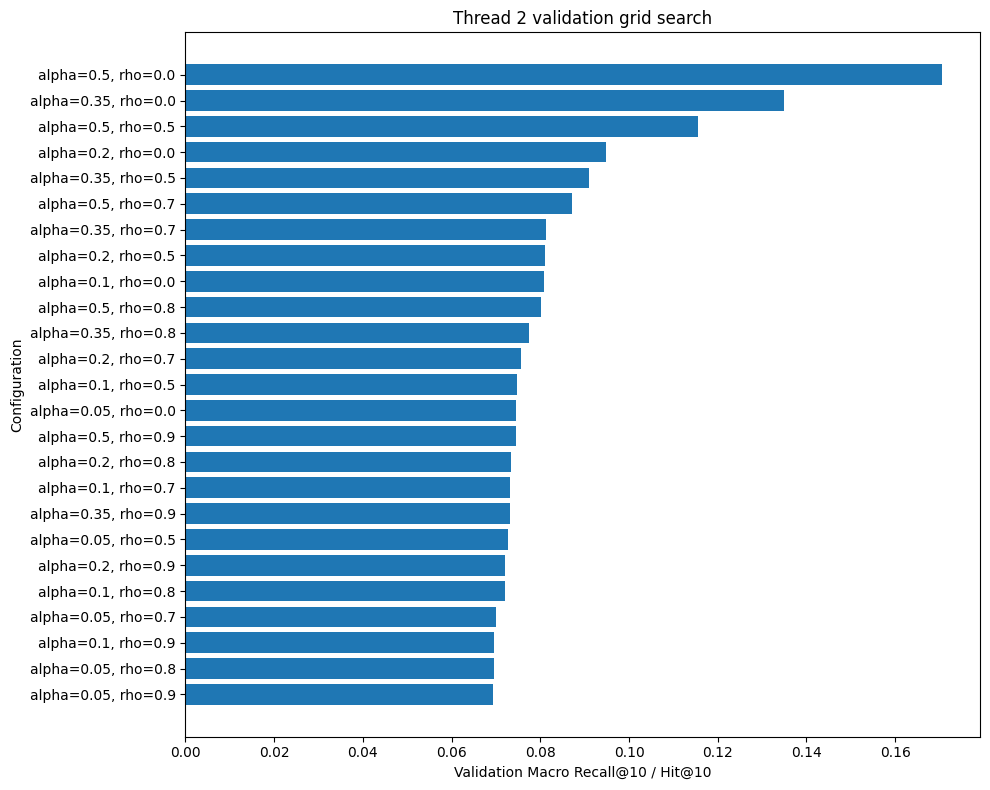

Saved validation grid plot to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_validation_alpha_rho_grid_recall10.png
Best non-zero rho config from validation:
  best_nonzero_alpha: 0.5
  best_nonzero_rho: 0.5


REPORT BEST NONZERO RHO alpha=0.5, rho=0.5:   0%|          | 0/14 [00:00<?, ?it/s]

Saved best non-zero rho report results to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_best_nonzero_rho_report_results.csv


,query,Pure_GDE_Recall@10,Identity_Blend_Recall@10,Delta_identity_minus_pure
0,"+Black_Hair, -Wavy_Hair",0.0569,0.1224,0.0655
1,+Blond_Hair,0.2011,0.1305,-0.0706
2,"+Chubby, -Young",0.0707,0.0343,-0.0364
3,+Eyeglasses,0.1702,0.1007,-0.0695
4,"+Eyeglasses, +Smiling",0.1184,0.0633,-0.0551
5,+Male,0.2241,0.0752,-0.1489
6,+Mustache,0.2241,0.2199,-0.0042
7,+Smiling,0.2452,0.2546,0.0094
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",0.0741,0.1111,0.0370
9,-Heavy_Makeup,0.1141,0.1612,0.0471



Pure GDE held-out report summary:
{'Macro_Recall@1': 0.03508461538461538, 'Macro_Precision@1': 0.03508461538461538, 'Macro_Recall@5': 0.10864615384615385, 'Macro_Precision@5': 0.026523076923076927, 'Macro_Recall@10': 0.15500769230769235, 'Macro_Precision@10': 0.02133076923076923}

Best identity-blended held-out report summary:
{'Macro_Recall@1': 0.021976923076923078, 'Macro_Precision@1': 0.021976923076923078, 'Macro_Recall@5': 0.07044615384615384, 'Macro_Precision@5': 0.017892307692307693, 'Macro_Recall@10': 0.11642307692307693, 'Macro_Precision@10': 0.015907692307692307}


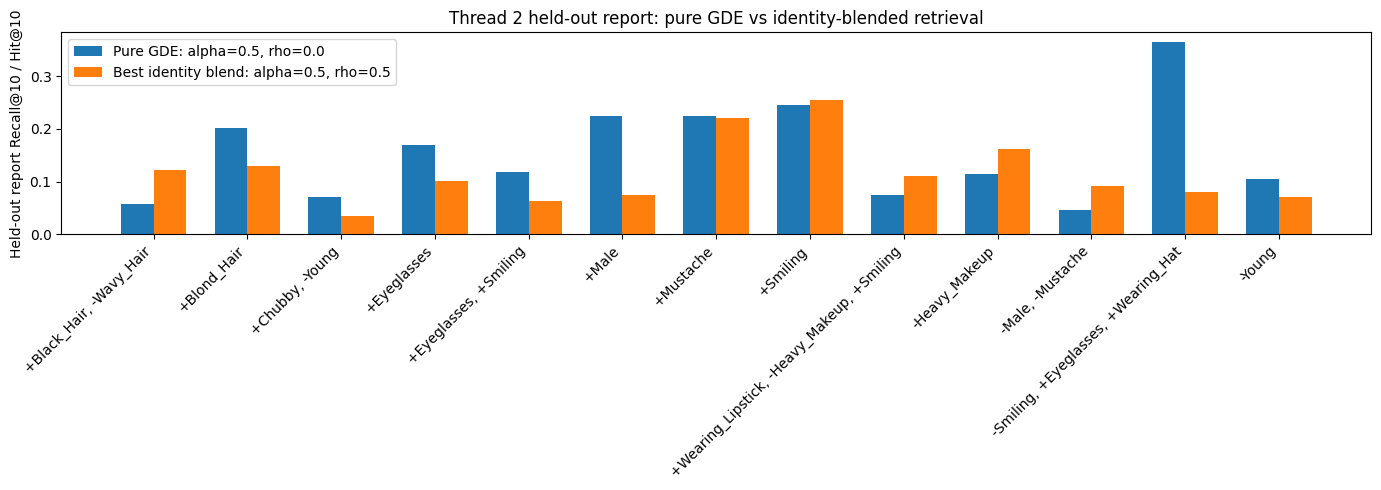

Saved held-out report comparison plot to: /content/drive/MyDrive/DL_Project/src/thread2_gde/thread2_report_pure_vs_identity_blend_recall10.png

Conclusion: validation selected rho = 0.0, so the final selected Thread 2 configuration is pure GDE. The identity-blending score did not improve validation performance.


In [24]:
metric_label = "Recall@10 / Hit@10" if RECALL_MODE == "hit" else "Recall@10"

# ------------------------------------------------------------
# Plot 1: validation grid search
# Make it horizontal so the alpha/rho labels are readable.
# ------------------------------------------------------------

validation_plot_df = validation_grid_df.copy()
validation_plot_df["config"] = validation_plot_df.apply(
    lambda row: f"alpha={row['alpha']}, rho={row['rho']}",
    axis=1,
)

validation_plot_df = validation_plot_df.sort_values(
    by="Macro_Recall@10",
    ascending=True,
).reset_index(drop=True)

plt.figure(figsize=(10, 8))

plt.barh(
    validation_plot_df["config"],
    validation_plot_df["Macro_Recall@10"],
)

plt.xlabel(f"Validation Macro {metric_label}")
plt.ylabel("Configuration")
plt.title("Thread 2 validation grid search")
plt.tight_layout()

GRID_PLOT_PATH = THREAD2_DIR / "thread2_validation_alpha_rho_grid_recall10.png"
plt.savefig(GRID_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Saved validation grid plot to:", GRID_PLOT_PATH)


# ------------------------------------------------------------
# Plot 2: pure GDE vs best identity-blended retrieval
# This is more useful than selected vs pure when selected rho = 0.
# ------------------------------------------------------------

nonzero_rho_grid_df = validation_grid_df[validation_grid_df["rho"] > 0.0].copy()

if len(nonzero_rho_grid_df) == 0:
    print("No rho > 0 configurations found. Skipping identity-blend comparison plot.")

else:
    nonzero_rho_grid_df = nonzero_rho_grid_df.sort_values(
        by=["Macro_Recall@10", "Macro_Precision@10"],
        ascending=False,
    ).reset_index(drop=True)

    best_nonzero_alpha = float(nonzero_rho_grid_df.loc[0, "alpha"])
    best_nonzero_rho = float(nonzero_rho_grid_df.loc[0, "rho"])

    print("Best non-zero rho config from validation:")
    print("  best_nonzero_alpha:", best_nonzero_alpha)
    print("  best_nonzero_rho:", best_nonzero_rho)

    nonzero_results_report_df = run_thread2_eval_alpha_rho(
        alpha=best_nonzero_alpha,
        rho=best_nonzero_rho,
        eval_annotations=report_annotations,
        recall_mode=RECALL_MODE,
        desc_prefix="REPORT BEST NONZERO RHO",
    )

    NONZERO_REPORT_RESULTS_PATH = THREAD2_DIR / "thread2_best_nonzero_rho_report_results.csv"
    nonzero_results_report_df.to_csv(NONZERO_REPORT_RESULTS_PATH, index=False)

    print("Saved best non-zero rho report results to:", NONZERO_REPORT_RESULTS_PATH)

    # Build comparison table.
    report_comparison_df = pure_results_report_df[["query", "Recall@10"]].rename(
        columns={"Recall@10": "Pure_GDE_Recall@10"}
    )

    nonzero_compare_df = nonzero_results_report_df[["query", "Recall@10"]].rename(
        columns={"Recall@10": "Identity_Blend_Recall@10"}
    )

    report_comparison_df = report_comparison_df.merge(
        nonzero_compare_df,
        on="query",
        how="inner",
    )

    report_comparison_df["Delta_identity_minus_pure"] = (
        report_comparison_df["Identity_Blend_Recall@10"]
        - report_comparison_df["Pure_GDE_Recall@10"]
    )

    display(report_comparison_df)

    print("\nPure GDE held-out report summary:")
    print(macro_summary(pure_results_report_df))

    print("\nBest identity-blended held-out report summary:")
    print(macro_summary(nonzero_results_report_df))

    # Plot pure GDE vs best non-zero rho.
    plt.figure(figsize=(14, 5))

    x = np.arange(len(report_comparison_df))
    width = 0.35

    plt.bar(
        x - width / 2,
        report_comparison_df["Pure_GDE_Recall@10"],
        width,
        label=f"Pure GDE: alpha={best_pure_alpha}, rho=0.0",
    )

    plt.bar(
        x + width / 2,
        report_comparison_df["Identity_Blend_Recall@10"],
        width,
        label=f"Best identity blend: alpha={best_nonzero_alpha}, rho={best_nonzero_rho}",
    )

    plt.xticks(
        x,
        report_comparison_df["query"],
        rotation=45,
        ha="right",
    )

    plt.ylabel(f"Held-out report {metric_label}")
    plt.title("Thread 2 held-out report: pure GDE vs identity-blended retrieval")
    plt.legend()
    plt.tight_layout()

    REPORT_QUERY_PLOT_PATH = THREAD2_DIR / "thread2_report_pure_vs_identity_blend_recall10.png"
    plt.savefig(REPORT_QUERY_PLOT_PATH, dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved held-out report comparison plot to:", REPORT_QUERY_PLOT_PATH)


# ------------------------------------------------------------
# Clear explanation for the notebook output.
# ------------------------------------------------------------

if best_rho == 0.0:
    print(
        "\nConclusion: validation selected rho = 0.0, so the final selected Thread 2 "
        "configuration is pure GDE. The identity-blending score did not improve validation performance."
    )
else:
    print(
        "\nConclusion: validation selected a non-zero rho, so the final selected Thread 2 "
        "configuration uses both GDE composition and identity-blended retrieval."
    )

**19. Qualitative visualization**

In [20]:
# Finds query-reference pairs with the highest number of hits in the top retrieved images.


print("Image folder exists:", IMG_DIR.exists())
print("Extracted image count:", len(list(IMG_DIR.glob("*.jpg"))))


def safe_load_image(idx):
    """
    Load image from the CelebA test dataset.
    Returns a gray placeholder if loading fails.
    """
    try:
        return celeba[idx][0]
    except Exception as e:
        print(f"Could not load image idx={idx}: {e}")
        placeholder = np.ones((218, 178, 3), dtype=np.uint8) * 220
        return Image.fromarray(placeholder)


def get_retrieval_info(
    eval_annotations,
    query_id,
    ref_position=0,
    topk=5,
    alpha=None,
    rho=None,
):
    """
    Compute retrieval results for one query-reference pair.
    Returns everything needed for visualization and ranking.
    """
    if alpha is None:
        alpha = best_alpha

    if rho is None:
        rho = best_rho

    ann = eval_annotations[query_id]

    ref_indices = [int(x) for x in ann["ground_truth"].keys()]
    ref_idx = ref_indices[ref_position]

    pos_attrs, neg_attrs = parse_query(ann["query"])
    ref_embedding = img_db[ref_idx]

    q = compose_gde_query(
        ref_embedding=ref_embedding,
        positive_attrs=pos_attrs,
        negative_attrs=neg_attrs,
        alpha=alpha,
    )

    retrieved = retrieve_topk_hybrid(
        query_embedding=q,
        ref_embedding=ref_embedding,
        ref_idx=ref_idx,
        k=topk,
        rho=rho,
    )

    gt = set(int(x) for x in ann["ground_truth"][str(ref_idx)])
    hit_flags = [idx in gt for idx in retrieved]
    hit_count = sum(hit_flags)

    return {
        "query_id": query_id,
        "source_annotation_id": int(ann.get("source_annotation_id", query_id)),
        "query": ann["query"],
        "ref_position": ref_position,
        "ref_idx": ref_idx,
        "retrieved": retrieved,
        "gt": gt,
        "hit_flags": hit_flags,
        "hit_count": hit_count,
        "topk": topk,
        "alpha": alpha,
        "rho": rho,
    }


def find_best_visual_examples(
    eval_annotations=report_annotations,
    topk=5,
    max_refs_per_query=10,
    num_examples=5,
    alpha=None,
    rho=None,
):
    """
    Search through query-reference pairs and keep the best ones.

    By default, this searches the held-out report split, not the validation split.
    """
    candidates = []

    for query_id, ann in enumerate(tqdm(eval_annotations, desc="Searching visual examples")):
        ref_indices = [int(x) for x in ann["ground_truth"].keys()]
        max_refs = min(len(ref_indices), max_refs_per_query)

        for ref_position in range(max_refs):
            info = get_retrieval_info(
                eval_annotations=eval_annotations,
                query_id=query_id,
                ref_position=ref_position,
                topk=topk,
                alpha=alpha,
                rho=rho,
            )

            candidates.append(info)

    candidates = sorted(
        candidates,
        key=lambda x: (x["hit_count"], -x["query_id"]),
        reverse=True,
    )

    return candidates[:num_examples], candidates


def show_retrieval_info(info, save=True):
    """
    Visualize one retrieval example.
    """
    query_id = info["query_id"]
    source_annotation_id = info["source_annotation_id"]
    ref_idx = info["ref_idx"]
    retrieved = info["retrieved"]
    gt = info["gt"]
    query_text = info["query"]
    hit_count = info["hit_count"]
    topk = info["topk"]
    alpha = info["alpha"]
    rho = info["rho"]

    all_indices = [ref_idx] + retrieved

    titles = [f"REF\nidx={ref_idx}\n{query_text}"]

    for idx in retrieved:
        hit_or_miss = "HIT" if idx in gt else "MISS"
        titles.append(f"{hit_or_miss}\nidx={idx}")

    plt.figure(figsize=(3 * len(all_indices), 4))

    for i, idx in enumerate(all_indices):
        img = safe_load_image(idx)

        plt.subplot(1, len(all_indices), i + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(titles[i], fontsize=10)

    plt.suptitle(
        f"Thread 2 held-out report example | source_ann={source_annotation_id} | "
        f"query_id={query_id} | hits={hit_count}/{topk} | alpha={alpha}, rho={rho}",
        y=1.05,
        fontsize=14,
    )

    plt.tight_layout()

    if save:
        save_path = THREAD2_DIR / (
            f"report_visual_source{source_annotation_id}_query{query_id}_ref{info['ref_position']}_"
            f"hits{hit_count}_alpha{alpha}_rho{rho}.png"
        )

        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print("Saved visual result to:", save_path)

    plt.show()

Image folder exists: True
Extracted image count: 19962


In [21]:
best_visual_examples, all_visual_candidates = find_best_visual_examples(
    eval_annotations=report_annotations,
    topk=5,
    max_refs_per_query=10,
    num_examples=5,
    alpha=best_alpha,
    rho=best_rho,
)

print("Top visual examples from held-out report split:")

for i, ex in enumerate(best_visual_examples):
    print(
        f"{i+1}. source_annotation_id={ex['source_annotation_id']}, "
        f"query_id={ex['query_id']}, "
        f"query='{ex['query']}', "
        f"ref_idx={ex['ref_idx']}, "
        f"hits={ex['hit_count']}/{ex['topk']}, "
        f"alpha={ex['alpha']}, rho={ex['rho']}"
    )

Searching visual examples:   0%|          | 0/14 [00:00<?, ?it/s]

Top visual examples from held-out report split:
1. source_annotation_id=0, query_id=0, query='+Smiling', ref_idx=28, hits=3/5, alpha=0.5, rho=0.0
2. source_annotation_id=1, query_id=1, query='+Eyeglasses', ref_idx=97, hits=2/5, alpha=0.5, rho=0.0
3. source_annotation_id=3, query_id=3, query='+Male', ref_idx=60, hits=2/5, alpha=0.5, rho=0.0
4. source_annotation_id=0, query_id=0, query='+Smiling', ref_idx=15, hits=1/5, alpha=0.5, rho=0.0
5. source_annotation_id=1, query_id=1, query='+Eyeglasses', ref_idx=60, hits=1/5, alpha=0.5, rho=0.0


Saved visual result to: /content/drive/MyDrive/DL_Project/src/thread2_gde/report_visual_source0_query0_ref6_hits3_alpha0.5_rho0.0.png


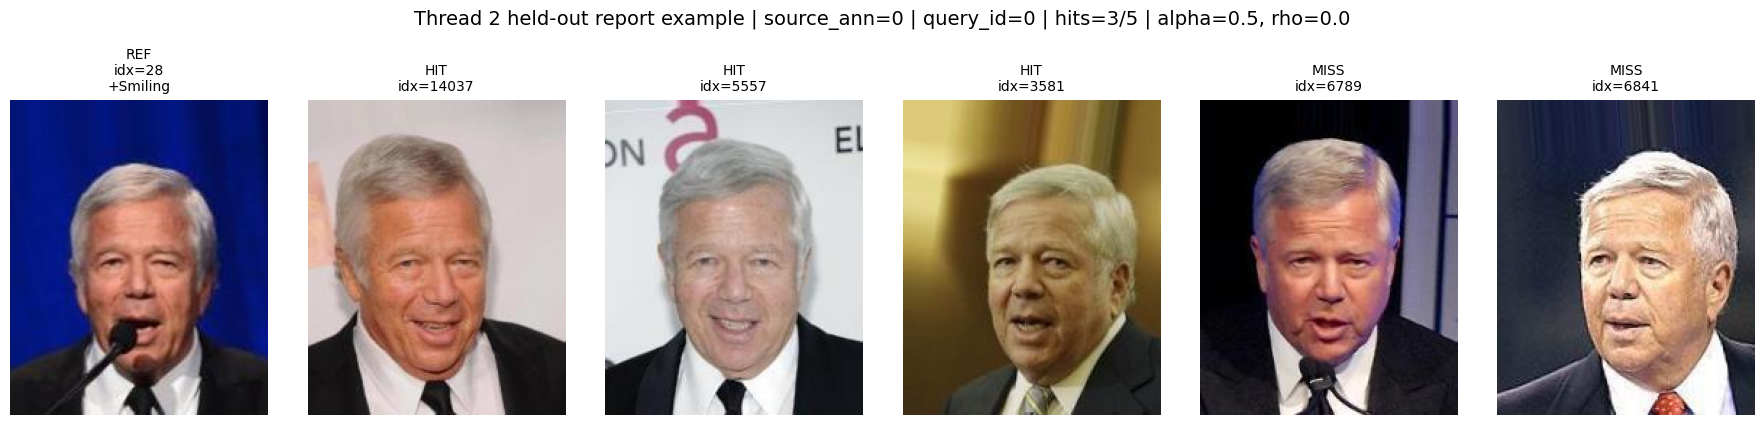

Saved visual result to: /content/drive/MyDrive/DL_Project/src/thread2_gde/report_visual_source1_query1_ref8_hits2_alpha0.5_rho0.0.png


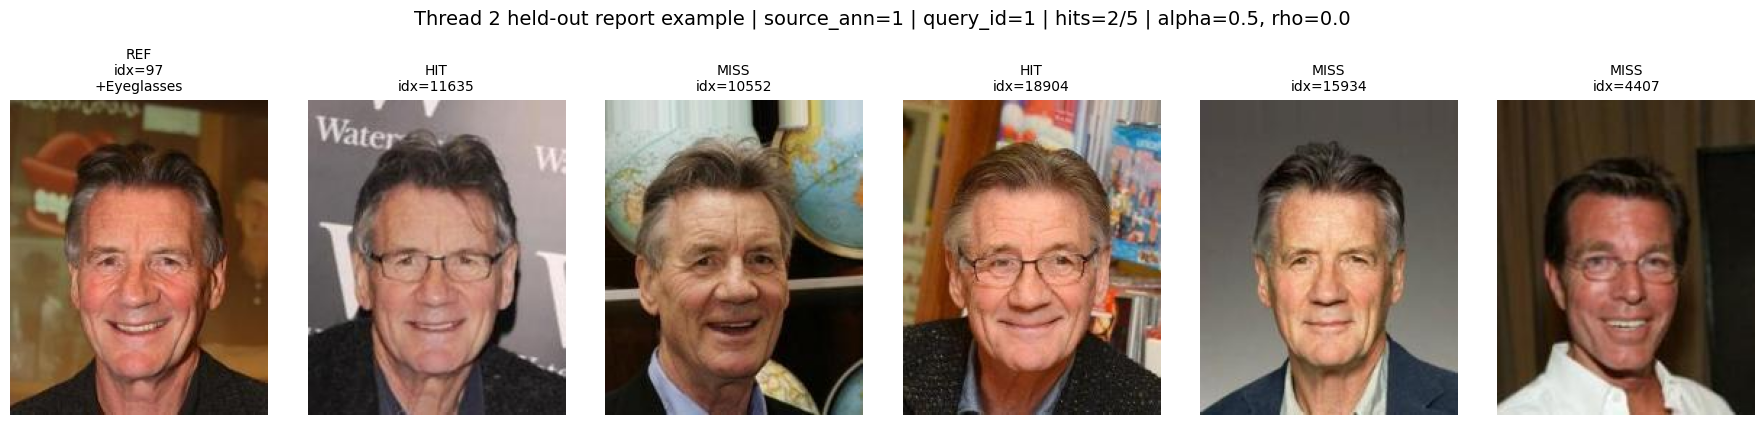

Saved visual result to: /content/drive/MyDrive/DL_Project/src/thread2_gde/report_visual_source3_query3_ref7_hits2_alpha0.5_rho0.0.png


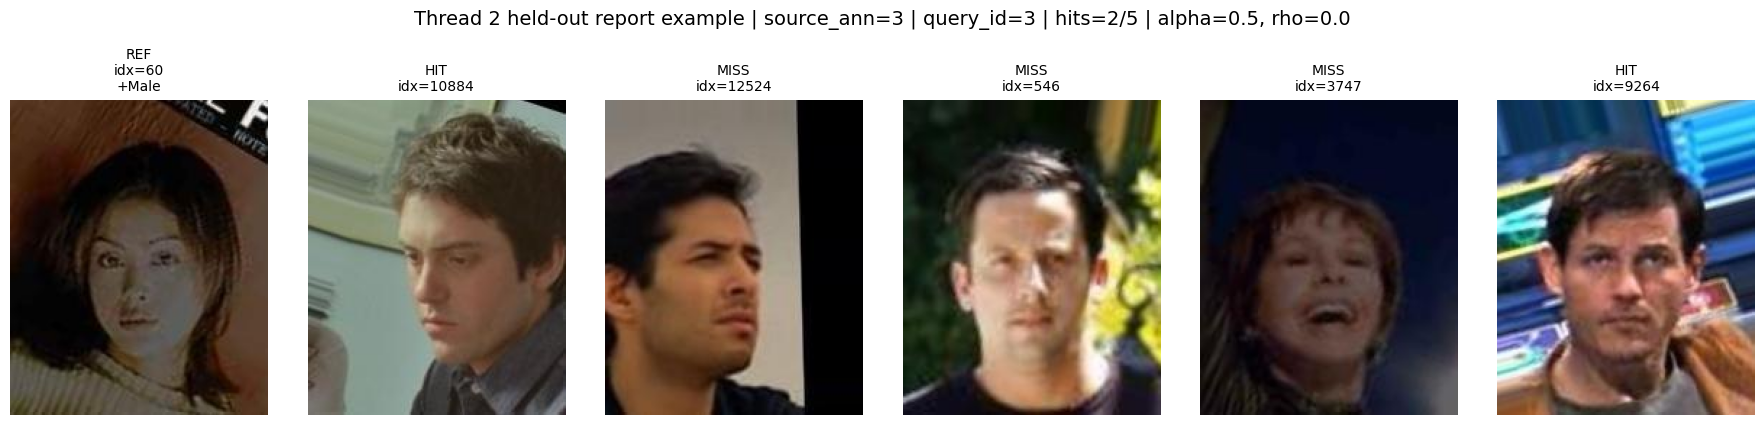

Saved visual result to: /content/drive/MyDrive/DL_Project/src/thread2_gde/report_visual_source0_query0_ref2_hits1_alpha0.5_rho0.0.png


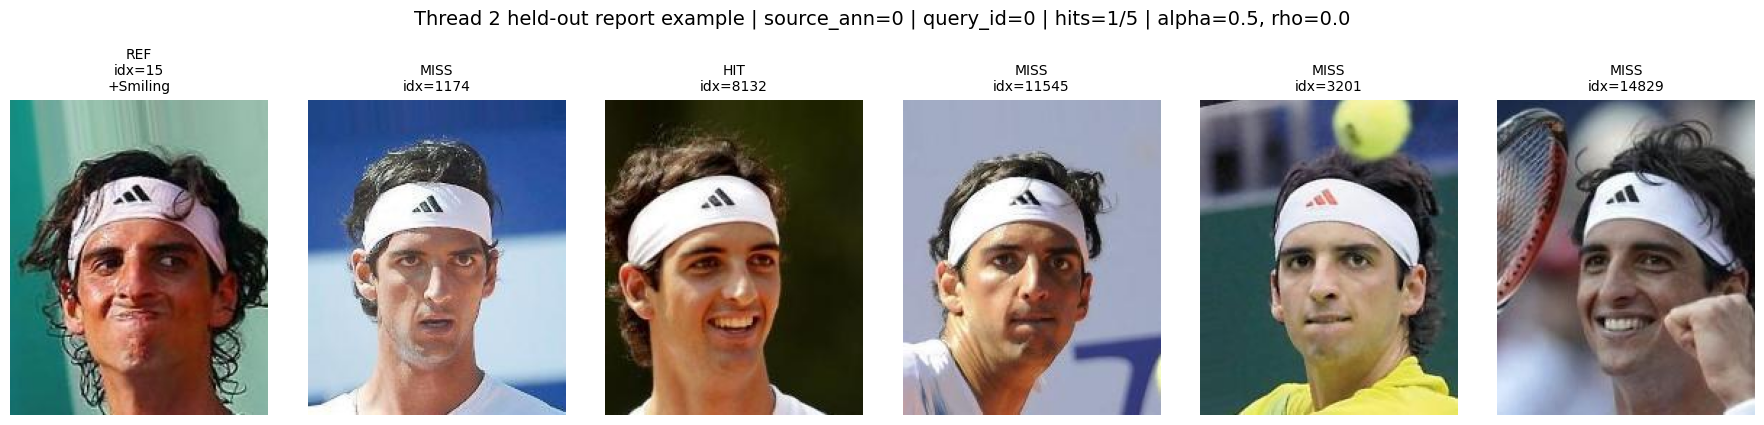

Saved visual result to: /content/drive/MyDrive/DL_Project/src/thread2_gde/report_visual_source1_query1_ref6_hits1_alpha0.5_rho0.0.png


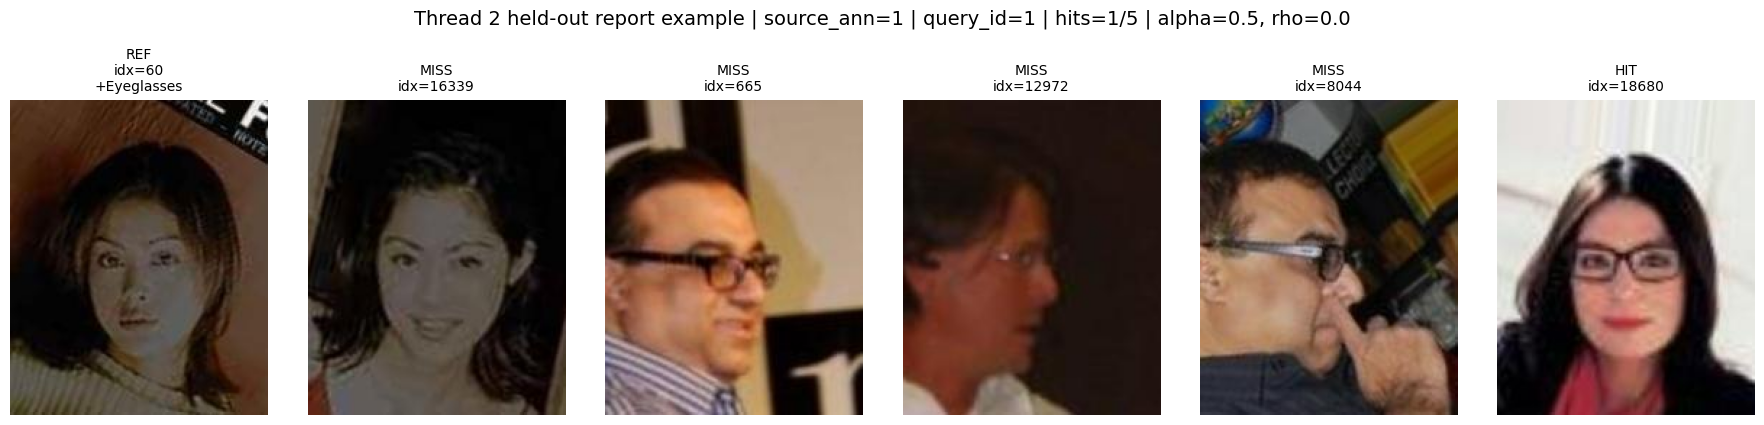

In [22]:
for ex in best_visual_examples:
    show_retrieval_info(ex, save=True)

## **19. Interpretation and conclusion**

Thread 2 implemented a **GDE-style geodesic composition method** for compositional image retrieval. Instead of using only text-embedding arithmetic like the baseline, this method builds **image-derived attribute directions** from CelebA image groups and applies the requested positive and negative edits in a manifold-aware way.

The validation sweep selected a very clean final configuration:

* **Best selected Thread 2 setting**: `alpha = 0.5`, `rho = 0.0`
* **Direction mode**: `hybrid`
* **Recall mode**: hit-based Recall@K

This result is important because `rho = 0.0` means that the best-performing configuration is **pure GDE**. In other words, the final Thread 2 result does not depend on the extra identity-blended retrieval score. The retrieval is based only on the composed geodesic query.

The notebook also tested identity-blended retrieval, where the score combines similarity to the edited query and similarity to the original reference image. However, the validation results showed that adding this identity-blending term did not improve performance. This suggests that, for Thread 2, the image-derived geodesic composition already preserved enough reference information, and additional identity weighting was unnecessary.

From the final Thread 2 results:

* On the **held-out report split**, Thread 2 achieved approximately `Recall@10 = 0.1550` and `Precision@10 = 0.0213`.
* On the **full mandatory evaluation list**, Thread 2 achieved approximately `Recall@10 = 0.1582` and `Precision@10 = 0.0219`.

Compared with the baseline arithmetic result reported in the shared summary table, where the baseline achieved `Recall@10 = 0.1059` and `Precision@10 = 0.0146`, Thread 2 performs substantially better overall. This means the GDE-style method successfully improves over naive CLIP arithmetic on this benchmark.

The most reasonable interpretation is that CelebA benefits from **image-derived attribute directions**. Attributes such as smiling, eyeglasses, mustache, or wearing hat are better represented when they are estimated from actual image groups rather than taken directly from CLIP text embeddings. This helps the model perform more meaningful edits in the retrieval space.

The use of `hybrid` direction construction also helped make the attribute directions more reliable. In this setup, CelebA attribute labels define the positive and negative image groups, while CLIP image-to-text confidence scores are used as a denoising signal. This reduces the effect of noisy or uncertain examples when building each attribute direction.

A key lesson from Thread 2 is that respecting the geometry of the CLIP embedding space matters. Simple arithmetic treats the embedding space as flat, but normalized CLIP embeddings behave more like points on a curved space. Thread 2 handles this more carefully by using geodesic operations, which likely explains the improvement over the baseline.

Therefore, the conclusion for Thread 2 is positive:

* the GDE-style geodesic composition works successfully
* image-derived attribute directions are more effective than naive text-vector arithmetic
* the validation sweep selected pure GDE, so the improvement is not caused by extra identity blending
* Thread 2 improves over the baseline arithmetic composition overall
* this makes Thread 2 a strong component to combine later with Thread 4's sign-aware positive and negative subspaces

Overall, Thread 2 shows that **manifold-aware image-derived composition is a useful improvement for compositional image retrieval on CelebA**.
